In [15]:
import anndata as ad 
import scanpy as sc 


import os
import pandas as pd 
import numpy as np
import decoupler as dc 

import gseapy as gp

#### Load Data

In [16]:
# load scRNAseq adata
adatas = {}

for file_name in os.listdir('../../data/Leblay_Single_Cell/GSE199359_RAW/'):
    adata = sc.read_10x_h5('../../data/Leblay_Single_Cell/GSE199359_RAW/' + file_name) 
    adata.var_names_make_unique()
    treatment_status_str = file_name[17:21].replace('_', "")
    treatment_status = [treatment_status_str for i in range(len(adata.obs))]
    adata.obs['treatment_status'] = treatment_status
    #print(treatment_status_str)
    adatas[file_name[11: 16]] = adata

adata = ad.concat(adatas, label='sample')




/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scan

In [17]:
atac_path = '../../data/Leblay_Single_Cell/ATACseq/'
atac = ad.read_h5ad(atac_path + 'scATACseq.h5ad')

/tmp/ipykernel_15544/3436442406.py:2: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  atac = ad.read_h5ad(atac_path + 'scATACseq.h5ad')


In [ ]:
print(atac.X)

In [19]:
adata.obs

,treatment_status,sample
AAACCTGTCACAACGT-1,Pre,P1498
AAACGGGAGGCTCATT-1,Pre,P1498
AAAGCAAAGCCCAATT-1,Pre,P1498
AAAGCAATCTCTTGAT-1,Pre,P1498
AAAGTAGGTTCGGCAC-1,Pre,P1498
...,...,...
TTTGTTGCACGACGAA-1,Pre,P1722
TTTGTTGCAGCGTATT-1,Pre,P1722
TTTGTTGGTAATGCTC-1,Pre,P1722
TTTGTTGTCCGGCTTT-1,Pre,P1722


In [ ]:
metadata = pd.read_csv("../../data/Leblay_Single_Cell/metadata.csv", sep='\t').set_index('Patient ID')

In [5]:
metadata['t11_14'] = [False if metadata.loc[p]['t(11;14) status'] == 'Negative' else True for p in metadata.index]
metadata

,Sex,Age (y),MM subtype,t(11;14) status,t(4;14) status,t(14;16) status,del13q status,del17p status,Stage (R-ISS),Number of prior therapies,Best response to venetoclax,Duration of response to venetoclax (mo),Prevenetoclax Sample,Postvenetoclax Sample,DNA_SEQ_Prevenetoclax Sample,DNA_SEQ_Postvenetoclax Sample,t11_14
Patient ID,,,,,,,,,,,,,,,,,
PM01,M,44,IgGκ,Positive (17% of the cells),Negative,Negative,Negative,Negative,II,4,VGPR,8.0,P1393,P1555,P1426,P1555,True
PM02,M,74,IgGκ,Negative,Negative,Negative,Negative,Negative,I,7,NaN,NaN,P1723,NaN,NaN,NaN,False
PM03,F,66,κ light chain,Negative,Negative,Negative,Negative,Negative,III,4,NaN,NaN,P1608,P1675,NaN,NaN,False
PM04,F,82,IgGκ,Negative,Negative,Negative,Negative,Negative,II,3,NaN,NaN,P1299,P1345,NaN,NaN,False
PM05,M,78,Λ light chain,Positive (97% of the cells),Negative,Negative,Negative,Positive (99% of cells),II,8,VGPR,21.0,P1643,NaN,NaN,NaN,True
PM06,M,65,IgGκ,Negative,Negative,Negative,Negative,Negative,III,4,NaN,NaN,P1752,NaN,NaN,NaN,False
PM07,M,69,IgGλ,Positive (88% of the cells),Negative,Negative,Negative,Positive (66% of cells),I,4,PR,4.0,P1389,P1479,P1389,P1479,True
PM08,M,60,IgAκ,Negative,Positive (17% of the cells),Negative,Negative,Negative,II,6,NaN,NaN,P1680,NaN,NaN,NaN,False
PM09,M,74,IgGλ,Positive (77% of the cells),Negative,Negative,Negative,Negative,I,4,VGPR,13.0,P1498,P1698,P1498,P1698,True


In [6]:
pre_ven_mapper = pd.Series(dict(zip(metadata['Prevenetoclax Sample'],metadata.index)))
post_ven_mapper = pd.Series(dict(zip(metadata['Postvenetoclax Sample'],metadata.index)))

mapper = pd.concat((pre_ven_mapper, post_ven_mapper))



#mapper_index_corrected = ['P1722' if mapper.loc[index] == 'PM15' else index for index in mapper.index]
#mapper.index = mapper_index_corrected

# need to remove P1627
adata = adata[adata.obs['sample'] != "P1627"].copy()


/tmp/ipykernel_32787/3191152140.py:12: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = adata[adata.obs['sample'] != "P1627"].copy()


In [7]:
mapper

P1393    PM01
P1723    PM02
P1608    PM03
P1299    PM04
P1643    PM05
P1752    PM06
P1389    PM07
P1680    PM08
P1498    PM09
P1217    PM10
P1388    PM11
P1751    PM12
P1396    PM13
P1395    PM14
P1722    PM15
P1555    PM01
NaN      PM15
P1675    PM03
P1345    PM04
P1479    PM07
P1698    PM09
P1438    PM10
P1809    PM12
P1461    PM13
P1606    PM14
dtype: str

In [8]:
patient_id = []
for sample_id in adata.obs['sample']:
    patient_id.append(mapper.loc[sample_id])

adata.obs['patient_id'] = patient_id

In [9]:
t11_14 = []

for patient_id in adata.obs['patient_id']:
    t11_14.append(metadata.loc[patient_id]['t11_14'])

adata.obs['t11_14'] = t11_14

In [10]:
adata.obs

,treatment_status,sample,patient_id,t11_14
AAACCTGTCACAACGT-1,Pre,P1498,PM09,True
AAACGGGAGGCTCATT-1,Pre,P1498,PM09,True
AAAGCAAAGCCCAATT-1,Pre,P1498,PM09,True
AAAGCAATCTCTTGAT-1,Pre,P1498,PM09,True
AAAGTAGGTTCGGCAC-1,Pre,P1498,PM09,True
...,...,...,...,...
TTTGTTGCACGACGAA-1,Pre,P1722,PM15,False
TTTGTTGCAGCGTATT-1,Pre,P1722,PM15,False
TTTGTTGGTAATGCTC-1,Pre,P1722,PM15,False
TTTGTTGTCCGGCTTT-1,Pre,P1722,PM15,False


#### Quality Control


In [11]:
adata.var['mt'] = adata.var_names.str.startswith("MT-")
adata.var['ribo'] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var['hb'] = adata.var_names.str.contains("^HB[^(P)]")

In [12]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo', 'hb'], inplace=True, log1p=True)

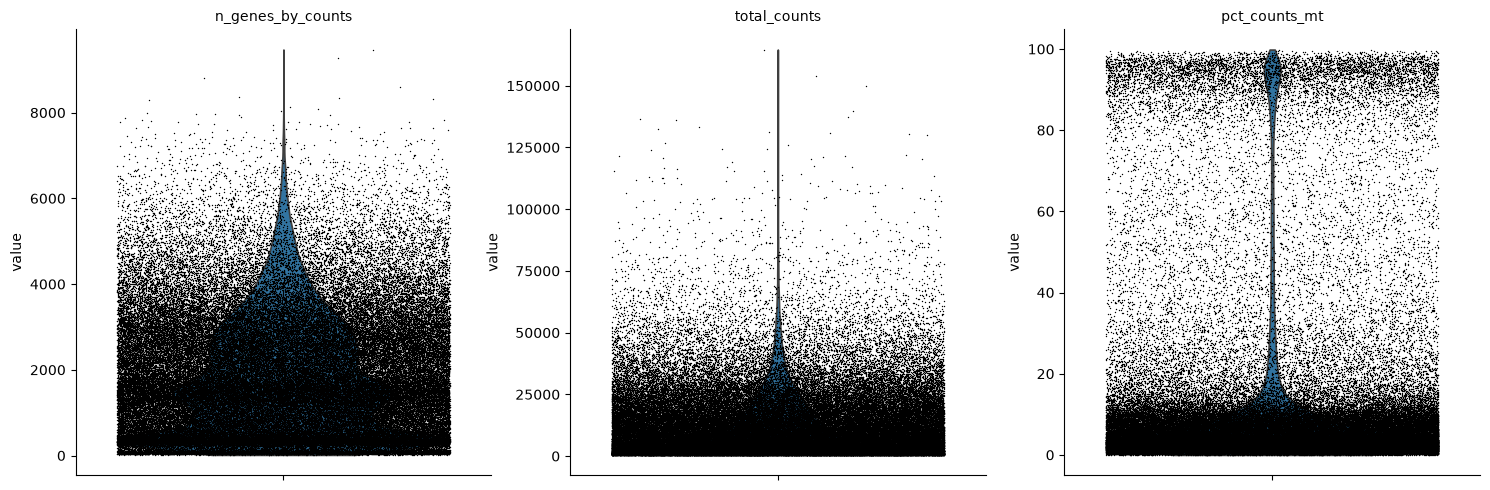

In [13]:
sc.pl.violin(adata,['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

In [14]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata,min_cells=3)
adata = adata[adata.obs['pct_counts_mt'] < 15].copy()



/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:164: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_obs(cell_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:164: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_obs(cell_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:281: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata._inplace_subset_var(gene_subset)
/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:281: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique

In [15]:
sc.pp.scrublet(adata, batch_key='sample')

/home/braemp4/code/venetoclax_project/single-cell-venv/lib/python3.14/site-packages/scanpy/preprocessing/_scrublet/__init__.py:195: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata_obs = adata.copy()


In [16]:
print(f'Number of predicted doublets: {len(adata.obs[adata.obs['predicted_doublet'] == True])}')
adata = adata[adata.obs['predicted_doublet'] == False]

Number of predicted doublets: 91


#### Normalization

In [17]:
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

/tmp/ipykernel_32787/3613107919.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata.layers['counts'] = adata.X.copy()
/usr/lib/python3.14/contextlib.py:141: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  return next(self.gen)
/usr/lib/python3.14/contextlib.py:148: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  next(self.gen)


#### Feature Selection


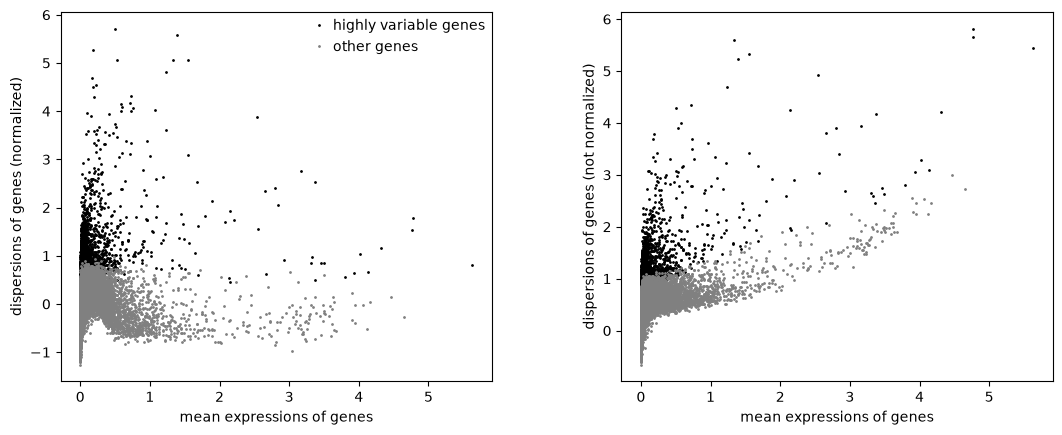

In [18]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key='sample')
sc.pl.highly_variable_genes(adata)

#### Dimensionality Reduction

- Allows us to see what principle components explain the majority of the variance
    - Looks like PC1-5
- We can also use PCA to see if variation is being driven by our QC variables
    - It looks like we need to filter mitochondrial genes

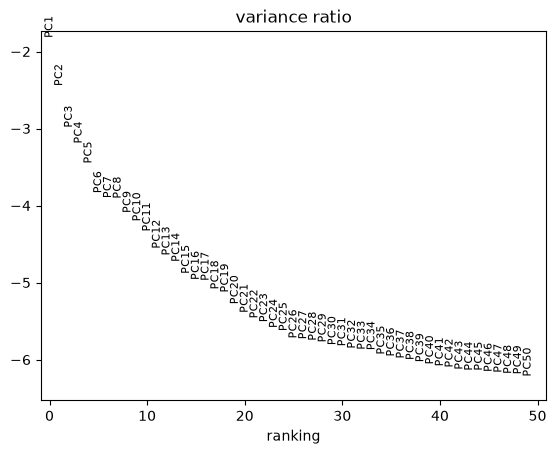

In [19]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True) 

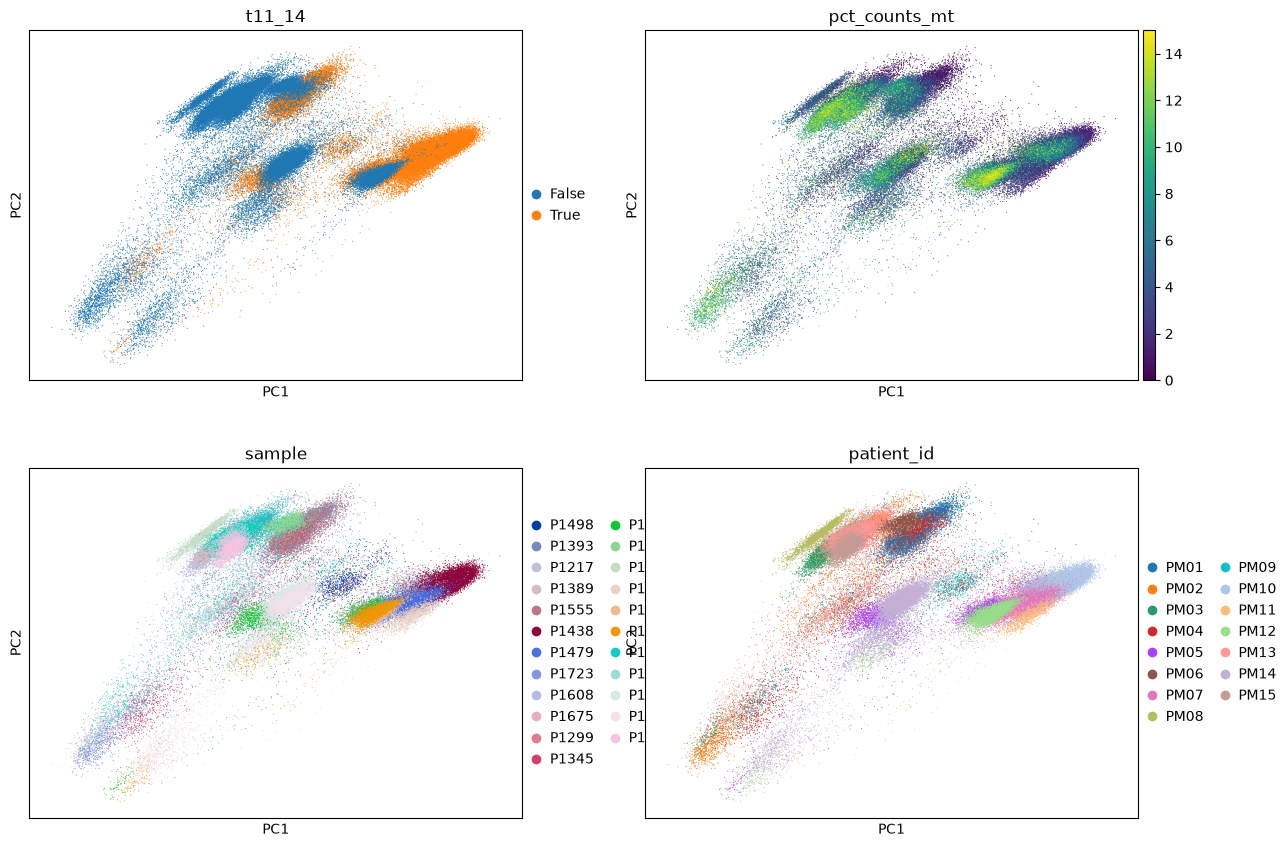

In [20]:

sc.pl.pca(adata, color=['t11_14', 'pct_counts_mt', 'sample', 'patient_id'], size=2, ncols=2)

#### UMAP and NN graph


In [21]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)


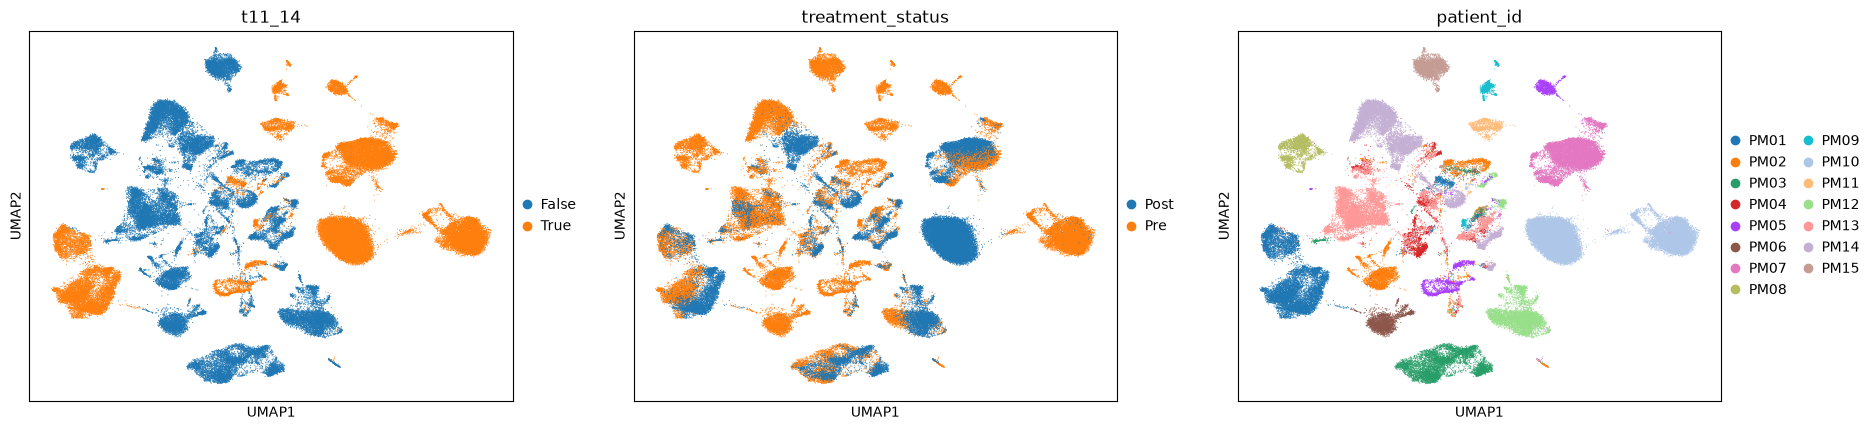

In [22]:
# UMAP using all samples

sc.pl.umap(adata, color=['t11_14', 'treatment_status', 'patient_id'], size=2)

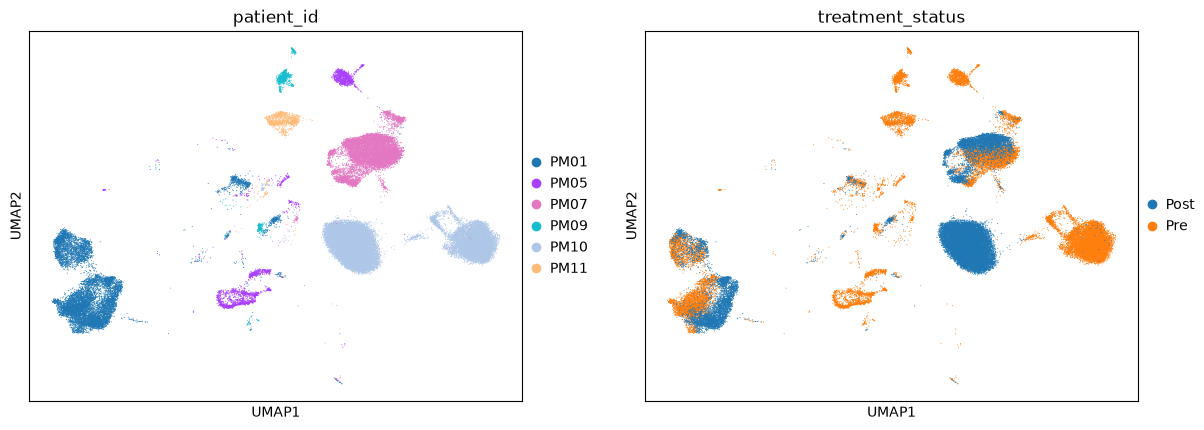

In [23]:
# UMAP with t11;14+ samples only
sc.pl.umap(adata[adata.obs['t11_14'] == True], color=['patient_id', 'treatment_status'], size=2, ncols=2)



#### Clustering

In [24]:
sc.tl.leiden(adata, resolution = 0.25, key_added='leiden_0.25',flavor='igraph', n_iterations=2)
sc.tl.leiden(adata, resolution = 0.5, key_added='leiden_0.5',flavor='igraph', n_iterations=2)
sc.tl.leiden(adata, resolution = 1.0, key_added='leiden_1.0',flavor='igraph', n_iterations=2)

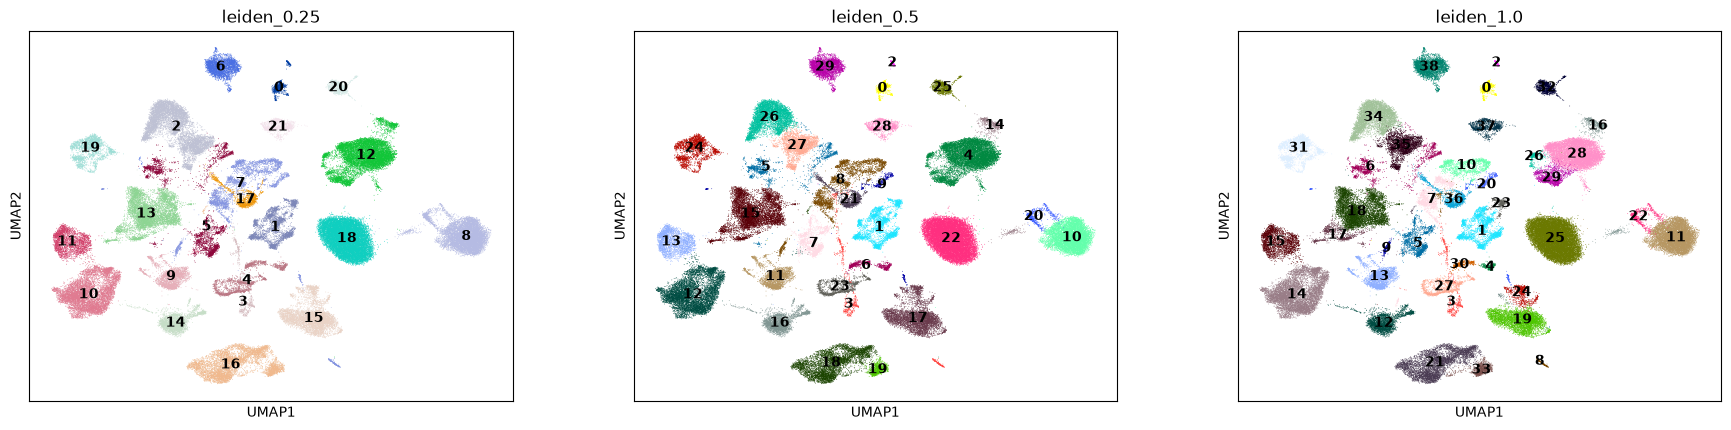

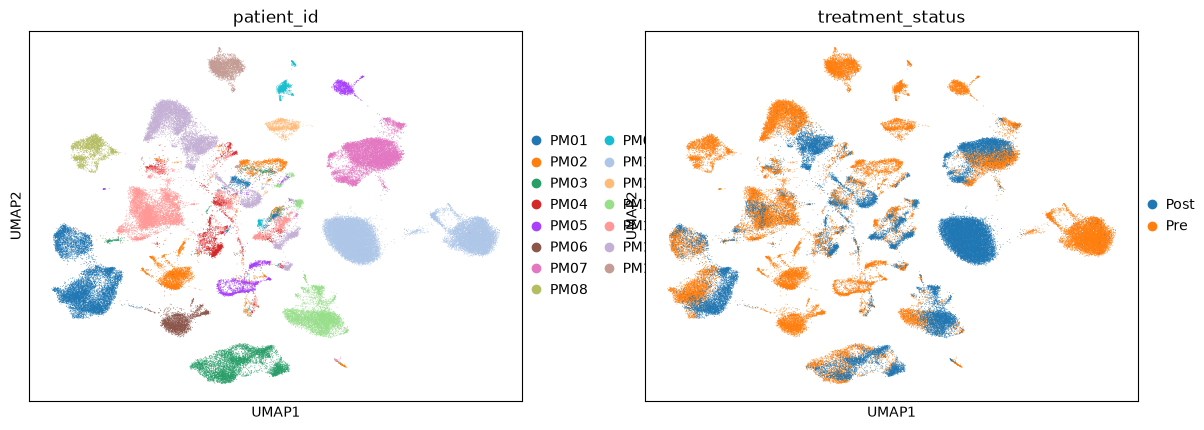

In [25]:
sc.pl.umap(adata, color=['leiden_0.25', 'leiden_0.5', 'leiden_1.0'], legend_loc='on data')
sc.pl.umap(adata, color=['patient_id', 'treatment_status'])